In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_test = pd.read_csv('loan-test.csv')
df_train = pd.read_csv('loan-train.csv')

In [3]:
df_test

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban
...,...,...,...,...,...,...,...,...,...,...,...,...
362,LP002971,Male,Yes,3+,Not Graduate,Yes,4009,1777,113.0,360.0,1.0,Urban
363,LP002975,Male,Yes,0,Graduate,No,4158,709,115.0,360.0,1.0,Urban
364,LP002980,Male,No,0,Graduate,No,3250,1993,126.0,360.0,NaN,Semiurban
365,LP002986,Male,Yes,0,Graduate,No,5000,2393,158.0,360.0,1.0,Rural


In [4]:
# data cleaning

df_train = df_train.dropna()

df_train[['LoanAmount', 
          'CoapplicantIncome', 
          'Loan_Amount_Term', 
          'Credit_History']]=df_train[['LoanAmount', 
                                       'CoapplicantIncome', 
                                       'Loan_Amount_Term', 
                                       'Credit_History']].apply(np.int64)

df_train=df_train.drop(['Dependents', 
                        'Loan_ID', 
                        'Loan_Amount_Term',
                        'Gender','Education','Married'], axis=1)

df_train

,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Loan_Status
1,No,4583,1508,128,1,Rural,N
2,Yes,3000,0,66,1,Urban,Y
3,No,2583,2358,120,1,Urban,Y
4,No,6000,0,141,1,Urban,Y
5,Yes,5417,4196,267,1,Urban,Y
...,...,...,...,...,...,...,...
609,No,2900,0,71,1,Rural,Y
610,No,4106,0,40,1,Rural,Y
611,No,8072,240,253,1,Urban,Y
612,No,7583,0,187,1,Urban,Y


In [5]:
# data transform

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

lb=LabelEncoder()
df_train['Self_Employed']=lb.fit_transform(df_train['Self_Employed'])
df_train['Property_Area']=lb.fit_transform(df_train['Property_Area'])
df_train['Loan_Status']=lb.fit_transform(df_train['Loan_Status'])

mx = MinMaxScaler()
df_train[['ApplicantIncome',
          'CoapplicantIncome',
          'LoanAmount']]= mx.fit_transform(df_train[['ApplicantIncome',
                                                     'CoapplicantIncome',
                                                     'LoanAmount']])

df_train

,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Loan_Status
1,0,0.054830,0.044567,0.201354,1,0,0
2,1,0.035250,0.000000,0.096447,1,2,1
3,0,0.030093,0.069687,0.187817,1,2,1
4,0,0.072356,0.000000,0.223350,1,2,1
5,1,0.065145,0.124006,0.436548,1,2,1
...,...,...,...,...,...,...,...
609,0,0.034014,0.000000,0.104907,1,0,1
610,0,0.048930,0.000000,0.052453,1,0,1
611,0,0.097984,0.007093,0.412860,1,2,1
612,0,0.091936,0.000000,0.301184,1,2,1


In [6]:
# splitting data

from sklearn.model_selection import train_test_split

X=df_train.drop('Loan_Status',axis=1)
y=df_train['Loan_Status']

X_test,X_train,y_test,y_train = train_test_split(X,y,test_size =0.3,random_state=42)

In [7]:
# decision tree

from sklearn.tree import DecisionTreeClassifier
tree=DecisionTreeClassifier(random_state=42)
tree.fit(X_train,y_train)
y_pred=tree.predict(X_test)

y_pred

array([1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1,

In [8]:
tree.score(X_test, y_test)

0.7261904761904762

In [9]:
df_new = pd.DataFrame({
    "Actual" : y_test,
    "Prediction" : y_pred
})

df_new

,Actual,Prediction
560,1,1
75,0,1
145,1,1
397,1,1
319,0,1
...,...,...
141,1,1
350,1,1
445,1,0
558,1,1


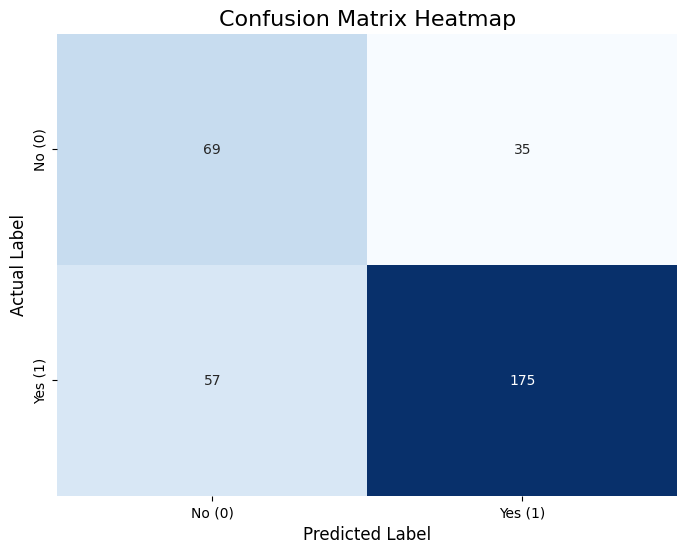

In [10]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(df_new["Actual"], df_new["Prediction"])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=["No (0)", "Yes (1)"], yticklabels=["No (0)", "Yes (1)"])

plt.title("Confusion Matrix Heatmap", fontsize=16)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.show()


In [11]:
# data testing

df_test = df_test.dropna()

df_test

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban
5,LP001054,Male,Yes,0,Not Graduate,Yes,2165,3422,152.0,360.0,1.0,Urban
...,...,...,...,...,...,...,...,...,...,...,...,...
361,LP002969,Male,Yes,1,Graduate,No,2269,2167,99.0,360.0,1.0,Semiurban
362,LP002971,Male,Yes,3+,Not Graduate,Yes,4009,1777,113.0,360.0,1.0,Urban
363,LP002975,Male,Yes,0,Graduate,No,4158,709,115.0,360.0,1.0,Urban
365,LP002986,Male,Yes,0,Graduate,No,5000,2393,158.0,360.0,1.0,Rural


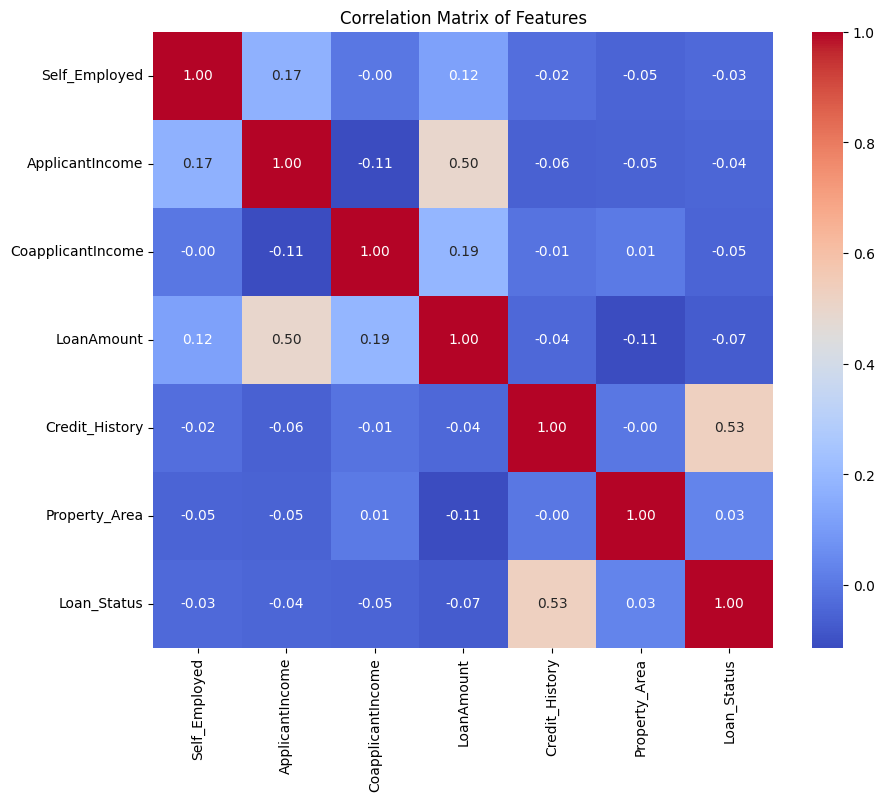

In [12]:
# cek korelasi antar kolom data

plt.figure(figsize=(10, 8))
sns.heatmap(df_train.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix of Features")
plt.show()

In [13]:
from sklearn.cluster import KMeans
from kneed import KneeLocator 

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X[["ApplicantIncome", "LoanAmount"]])
    wcss.append(kmeans.inertia_)

knee_locator = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee_locator.knee

clusterer= KMeans(n_clusters=optimal_k, init='k-means++')
clusterer.fit(X[["ApplicantIncome", "LoanAmount"]])
X["Cluster"] = clusterer.predict(X[["ApplicantIncome", "LoanAmount"]])

print(f"Optimal number of clusters (K): {optimal_k}")

Optimal number of clusters (K): 3


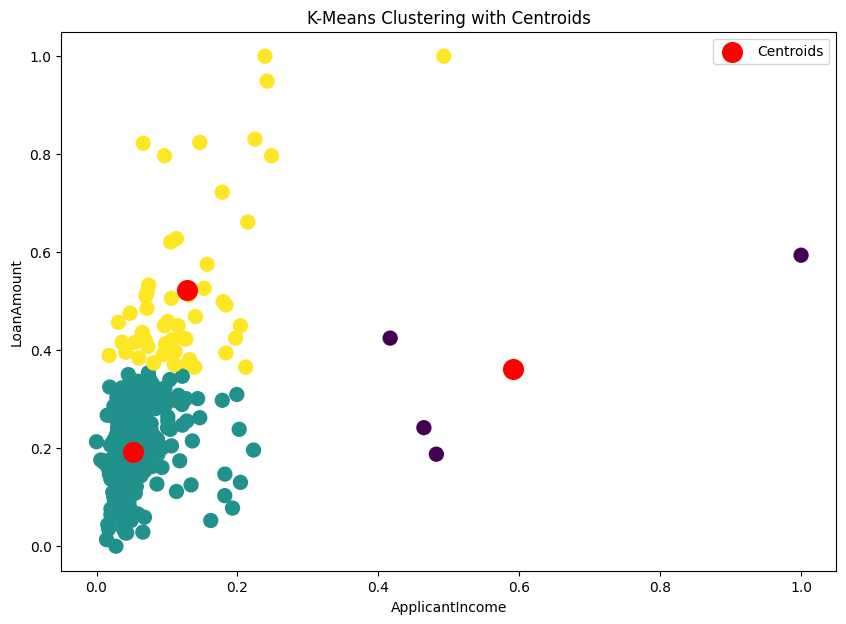

In [14]:
clusterer= KMeans(n_clusters=optimal_k, init='k-means++')
clusterer.fit(X[["ApplicantIncome", "LoanAmount"]])
X["Cluster"] = clusterer.predict(X[["ApplicantIncome", "LoanAmount"]])

centroids = clusterer.cluster_centers_

plt.figure(figsize=(10, 7))
plt.scatter(X['ApplicantIncome'], X['LoanAmount'], c=X['Cluster'], cmap='viridis', s=100)
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='red', label='Centroids')
plt.xlabel('ApplicantIncome')
plt.ylabel('LoanAmount')
plt.title('K-Means Clustering with Centroids')
plt.legend()
plt.show()